threads: 6
GPU: NVIDIA GeForce RTX 3070 Ti (7.7 GB)


/tmp/ipykernel_989792/4146239043.py:32: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding='latin1')


train: (50000, 3, 32, 32)   test: (10000, 3, 32, 32)


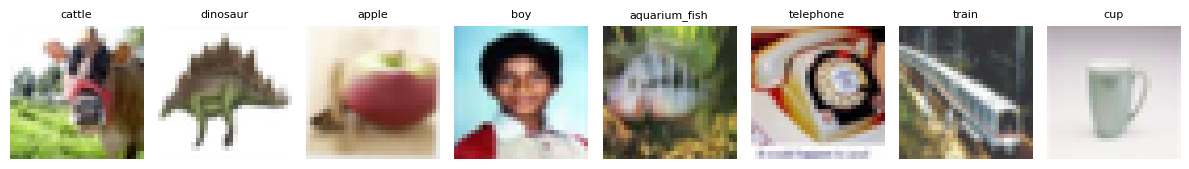

In [1]:
#N1: imports + threads + load CIFAR-100 (pickled files: meta, train, test), kept in colour

import os
N_THREADS = 6                                    # Baby-U: 12 cores, the GPU does the training (6 leaves room for a 2nd notebook)
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)   # must be set BEFORE importing torch/numpy
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

import pickle, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(N_THREADS)                 # PyTorch uses only these cores
print("threads:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")
    torch.backends.cuda.matmul.allow_tf32 = True     # RTX 30xx: faster float32 matrix products, same results to ~3 digits
    torch.backends.cudnn.allow_tf32 = True
else:
    print("no GPU found: running on the CPU (much slower)")

CPU_SLOT = 0     # only used on the 64-core Fatbaby: 0 -> cores 0-15, 1 -> 16-31, ... (Baby-U skips this)
if (os.cpu_count() or 0) >= 64:
    os.sched_setaffinity(0, range(16 * CPU_SLOT, 16 * CPU_SLOT + 16))
    print(f"pinned to cores {16 * CPU_SLOT}-{16 * CPU_SLOT + 15}")

BASE = '/home/worker/Scaricati/cifar'   # CHANGE to the folder on Baby-U that holds meta, train, test

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

meta  = unpickle(os.path.join(BASE, 'meta'))
train = unpickle(os.path.join(BASE, 'train'))
test  = unpickle(os.path.join(BASE, 'test'))
fine_names = meta['fine_label_names']            # 100 names, index = fine label

# each row = 1024 red + 1024 green + 1024 blue values -> keep colour: [N, 3, 32, 32] (no grayscale, no resizing)
x_train_all = np.asarray(train['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_train_all = np.array(train['fine_labels'])
x_test_all  = np.asarray(test['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_test_all  = np.array(test['fine_labels'])
print(f"train: {x_train_all.shape}   test: {x_test_all.shape}")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for k in range(8):
    axes[k].imshow(x_train_all[k].transpose(1, 2, 0))
    axes[k].set_title(fine_names[y_train_all[k]], fontsize=8)
    axes[k].axis('off')
plt.tight_layout(); plt.show()

In [2]:
#N2: defining 20 problems: the 20 CIFAR-100 superclasses, 5 fine classes each (same as the MLP notebooks)

SCRIPT_NAMES = ["P1_aquatic", "P2_fish", "P3_flowers", "P4_containers", "P5_produce",
                "P6_devices", "P7_furniture", "P8_insects", "P9_carnivores", "P10_outdoor_things",
                "P11_outdoor_scenes", "P12_omni_herbivores", "P13_medium_mammals", "P14_invertebrates", "P15_people",
                "P16_reptiles", "P17_small_mammals", "P18_trees", "P19_vehicles_1", "P20_vehicles_2"]

GROUP_CLASS_NAMES = [
    ["beaver", "dolphin", "otter", "seal", "whale"],                     # P1
    ["aquarium_fish", "flatfish", "ray", "shark", "trout"],              # P2
    ["orchid", "poppy", "rose", "sunflower", "tulip"],                   # P3
    ["bottle", "bowl", "can", "cup", "plate"],                           # P4
    ["apple", "mushroom", "orange", "pear", "sweet_pepper"],             # P5
    ["clock", "keyboard", "lamp", "telephone", "television"],            # P6
    ["bed", "chair", "couch", "table", "wardrobe"],                      # P7
    ["bee", "beetle", "butterfly", "caterpillar", "cockroach"],          # P8
    ["bear", "leopard", "lion", "tiger", "wolf"],                        # P9
    ["bridge", "castle", "house", "road", "skyscraper"],                 # P10
    ["cloud", "forest", "mountain", "plain", "sea"],                     # P11
    ["camel", "cattle", "chimpanzee", "elephant", "kangaroo"],           # P12
    ["fox", "porcupine", "possum", "raccoon", "skunk"],                  # P13
    ["crab", "lobster", "snail", "spider", "worm"],                      # P14
    ["baby", "boy", "girl", "man", "woman"],                             # P15
    ["crocodile", "dinosaur", "lizard", "snake", "turtle"],              # P16
    ["hamster", "mouse", "rabbit", "shrew", "squirrel"],                 # P17
    ["maple_tree", "oak_tree", "palm_tree", "pine_tree", "willow_tree"], # P18
    ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],           # P19
    ["lawn_mower", "rocket", "streetcar", "tank", "tractor"],            # P20
]

name_to_fine = {n: i for i, n in enumerate(fine_names)}
GROUP_LABELS = [[name_to_fine[n] for n in grp] for grp in GROUP_CLASS_NAMES]
for name, names, labels in zip(SCRIPT_NAMES, GROUP_CLASS_NAMES, GROUP_LABELS):
    print(f"{name:20s}", list(zip(names, labels)))
print("\n20 problems, 5 classes each, all 100 CIFAR-100 fine classes used")

P1_aquatic           [('beaver', 4), ('dolphin', 30), ('otter', 55), ('seal', 72), ('whale', 95)]
P2_fish              [('aquarium_fish', 1), ('flatfish', 32), ('ray', 67), ('shark', 73), ('trout', 91)]
P3_flowers           [('orchid', 54), ('poppy', 62), ('rose', 70), ('sunflower', 82), ('tulip', 92)]
P4_containers        [('bottle', 9), ('bowl', 10), ('can', 16), ('cup', 28), ('plate', 61)]
P5_produce           [('apple', 0), ('mushroom', 51), ('orange', 53), ('pear', 57), ('sweet_pepper', 83)]
P6_devices           [('clock', 22), ('keyboard', 39), ('lamp', 40), ('telephone', 86), ('television', 87)]
P7_furniture         [('bed', 5), ('chair', 20), ('couch', 25), ('table', 84), ('wardrobe', 94)]
P8_insects           [('bee', 6), ('beetle', 7), ('butterfly', 14), ('caterpillar', 18), ('cockroach', 24)]
P9_carnivores        [('bear', 3), ('leopard', 42), ('lion', 43), ('tiger', 88), ('wolf', 97)]
P10_outdoor_things   [('bridge', 12), ('castle', 17), ('house', 37), ('road', 68), ('skysc

In [3]:
#N3: building 20 datasets: colour 3x32x32, standardized per problem and per colour channel
#    every problem has THREE sets of images:
#      training images  2,250 (450 per class)  the network learns from these
#      held-out images    250 (50 per class, taken from the 500 training images of each class)
#                             -> early stopping and choosing the learning rate; the network never learns from them
#      test images        500 (100 per class)  only for the final result (N7), never for a decision

VAL_PER_CLASS = 50

rng = np.random.default_rng(0)    # fixed: the same held-out images as the TUNING = True runs of the earlier notebooks
X_tr, Y_tr, X_val, Y_val, X_te, Y_te = [], [], [], [], [], []
for m in range(20):
    xs_tr, ys_tr, xs_val, ys_val, xs_te, ys_te = [], [], [], [], [], []
    for new_label, old_label in enumerate(GROUP_LABELS[m]):          # labels 0-4 = position in the group list
        tr = x_train_all[y_train_all == old_label]                   # 500 training images of this class
        te = x_test_all[y_test_all == old_label]                     # 100 test images of this class
        perm = rng.permutation(len(tr))
        va, tr = tr[perm[:VAL_PER_CLASS]], tr[perm[VAL_PER_CLASS:]]   # 50 held-out, 450 to learn from
        xs_tr.append(tr); ys_tr.append(np.full(len(tr), new_label))
        xs_val.append(va); ys_val.append(np.full(len(va), new_label))
        xs_te.append(te); ys_te.append(np.full(len(te), new_label))
    x_tr = torch.tensor(np.concatenate(xs_tr), dtype=torch.float32)  # [2250, 3, 32, 32]
    x_val = torch.tensor(np.concatenate(xs_val), dtype=torch.float32)  # [250, 3, 32, 32]
    x_te = torch.tensor(np.concatenate(xs_te), dtype=torch.float32)  # [500, 3, 32, 32]
    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)                    # one mean and std per colour channel,
    std  = x_tr.std(dim=(0, 2, 3), keepdim=True)                     # from this problem's training images only
    X_tr.append((x_tr - mean) / std); Y_tr.append(torch.tensor(np.concatenate(ys_tr), dtype=torch.long))
    X_val.append((x_val - mean) / std); Y_val.append(torch.tensor(np.concatenate(ys_val), dtype=torch.long))
    X_te.append((x_te - mean) / std); Y_te.append(torch.tensor(np.concatenate(ys_te), dtype=torch.long))
    print(f"{SCRIPT_NAMES[m]:20s} train {len(x_tr):5d}  held-out {len(x_val):4d}  test {len(x_te):4d}  "
          f"channel means {[round(v, 1) for v in mean.flatten().tolist()]}")

X_tr, Y_tr   = torch.stack(X_tr), torch.stack(Y_tr)     # [20, 2250, 3, 32, 32] and [20, 2250]  (every problem has the same size)
X_val, Y_val = torch.stack(X_val), torch.stack(Y_val)   # [20, 250, 3, 32, 32]  and [20, 250]
X_te, Y_te   = torch.stack(X_te), torch.stack(Y_te)     # [20, 500, 3, 32, 32]  and [20, 500]
print(f"\nX_tr {tuple(X_tr.shape)}   X_val {tuple(X_val.shape)} (held-out)   X_te {tuple(X_te.shape)} (test)")

P1_aquatic           train  2250  held-out  250  test  500  channel means [108.1, 122.2, 127.2]
P2_fish              train  2250  held-out  250  test  500  channel means [106.2, 117.8, 116.6]
P3_flowers           train  2250  held-out  250  test  500  channel means [133.4, 104.0, 78.0]
P4_containers        train  2250  held-out  250  test  500  channel means [148.5, 139.3, 130.4]
P5_produce           train  2250  held-out  250  test  500  channel means [153.0, 125.4, 91.9]
P6_devices           train  2250  held-out  250  test  500  channel means [142.2, 136.9, 134.0]
P7_furniture         train  2250  held-out  250  test  500  channel means [155.4, 137.4, 124.5]
P8_insects           train  2250  held-out  250  test  500  channel means [141.8, 136.9, 109.6]
P9_carnivores        train  2250  held-out  250  test  500  channel means [120.2, 111.9, 94.7]
P10_outdoor_things   train  2250  held-out  250  test  500  channel means [123.7, 130.0, 130.4]
P11_outdoor_scenes   train  2250  held-out 

In [4]:
#N4: settings, batches, augmentation and the ViT (same code for independent and compound)

DEVICE        = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_PROBLEMS  = 20
CLASSES_PER   = 5

IMG, PATCH, CH = 32, 4, 3
N_PATCHES     = (IMG // PATCH) ** 2        # 64 patches per image (8 x 8)
PATCH_DIM     = PATCH * PATCH * CH         # 48 numbers per patch (4 x 4 x 3)
TOKENS        = N_PATCHES + 1              # 64 patches + 1 CLS token = 65
D             = 128                        # numbers per token
DEPTH         = 6                          # encoder blocks
HEADS         = 4                          # 4 heads x 32 dims
MLP_DIM       = 256                        # MLP inside each block: 128 -> 256 -> 128

BATCH_SIZE    = 32                         # per problem per step -> 640 images per step
LEARNING_RATES = [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3]   # tried one after the other in N6 (before: only 1e-3)
WEIGHT_DECAY  = 0.05
NUM_EPOCHS    = 100                        # at most 100 epochs: early stopping can end a run sooner
PATIENCE      = 10                         # early stopping: stop when the held-out accuracy has not improved for 10 epochs in a row
WARMUP_EPOCHS = 5
N_RUNS        = 5                          # sweep (N6): runs for EACH learning rate
N_FINAL_RUNS  = 50                         # final (N7): runs with the best learning rate
PRINT_EVERY_EPOCHS = 10                    # print one line every 10 epochs (the early-stopping check itself runs after EVERY epoch)
PRINT_EVERY   = 1
N_TRAIN       = X_tr.shape[1]                       # 2,250 per problem (50 per class are held out)
STEPS_PER_EPOCH = N_TRAIN // BATCH_SIZE             # 70: one pass over each problem
TOTAL_STEPS   = NUM_EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS  = WARMUP_EPOCHS * STEPS_PER_EPOCH

X_tr, Y_tr, X_te, Y_te = X_tr.to(DEVICE), Y_tr.to(DEVICE), X_te.to(DEVICE), Y_te.to(DEVICE)   # ~0.7 GB, stays on the GPU
X_val, Y_val = X_val.to(DEVICE), Y_val.to(DEVICE)

USE_AMP = DEVICE == 'cuda'       # bfloat16 mixed precision on the GPU tensor cores (~2x faster); the weight sets stay float32

def amp():
    return torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AMP)

# every weight tensor of one ViT: [out, in]  (no biases; LayerNorm has no learnable gain or bias)
SHAPES = {'patch': (D, PATCH_DIM), 'cls': (D,), 'pos': (TOKENS, D), 'head': (CLASSES_PER, D)}
for l in range(DEPTH):
    SHAPES[f'b{l}.qkv']  = (3 * D, D)       # Q, K, V together: 128 -> 384
    SHAPES[f'b{l}.proj'] = (D, D)           # joins the 4 heads: 128 -> 128
    SHAPES[f'b{l}.fc1']  = (MLP_DIM, D)     # 128 -> 256
    SHAPES[f'b{l}.fc2']  = (D, MLP_DIM)     # 256 -> 128
PARAMS_PER_VIT = sum(math.prod(s) for s in SHAPES.values())      # 801,664


def new_weight_sets(n_sets):
    """n_sets complete copies of every ViT tensor, stored as [n_sets, out, in]; small random start (std 0.02)"""
    G = {}
    for k, s in SHAPES.items():
        t = torch.empty(n_sets, *s, device=DEVICE)
        nn.init.trunc_normal_(t, std=0.02, a=-0.04, b=0.04)
        G[k] = nn.Parameter(t)
    return G


def lr_factor(step):
    """linear warmup for WARMUP_EPOCHS, then cosine decay to 0 at the last step"""
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * p))


class Batches:
    """one batch of 32 per problem per step; each problem's images are reshuffled after every full pass"""
    def __init__(self):
        self.pos = N_TRAIN
    def next(self):
        if self.pos + BATCH_SIZE > N_TRAIN:
            self.perm = torch.argsort(torch.rand(NUM_PROBLEMS, N_TRAIN, device=DEVICE), dim=1)
            self.pos = 0
        idx = self.perm[:, self.pos:self.pos + BATCH_SIZE]                 # [20, 32]
        self.pos += BATCH_SIZE
        rows = torch.arange(NUM_PROBLEMS, device=DEVICE)[:, None]
        return X_tr[rows, idx], Y_tr[rows, idx]                            # [20, 32, 3, 32, 32], [20, 32]


def augment(x):
    """training only: random crop (pad 4, crop 32x32) + random horizontal flip, a different one for every image"""
    M, Bsz = x.shape[:2]
    x = x.reshape(M * Bsz, CH, IMG, IMG)
    xp = F.pad(x, (4, 4, 4, 4)).permute(0, 2, 3, 1)                       # [N, 40, 40, 3]; padding 0 = channel mean
    N = xp.shape[0]
    ox = torch.randint(0, 9, (N,), device=x.device)
    oy = torch.randint(0, 9, (N,), device=x.device)
    ar = torch.arange(IMG, device=x.device)
    rows = (oy[:, None] + ar)[:, :, None]                                  # [N, 32, 1]
    cols = (ox[:, None] + ar)[:, None, :]                                  # [N, 1, 32]
    out = xp[torch.arange(N, device=x.device)[:, None, None], rows, cols].permute(0, 3, 1, 2)   # [N, 3, 32, 32]
    flip = torch.rand(N, device=x.device) < 0.5
    out = torch.where(flip[:, None, None, None], out.flip(3), out)
    return out.reshape(M, Bsz, CH, IMG, IMG)


def vit_forward(x, W):
    """x: [M, B, 3, 32, 32] images of M problems; W: every tensor as [M, out, in] = one ViT per problem.
       returns [M, B, 5] scores. All M problems run at the same time, each with its own weights."""
    M, Bsz = x.shape[:2]
    p = x.unfold(3, PATCH, PATCH).unfold(4, PATCH, PATCH)                  # [M, B, 3, 8, 8, 4, 4]
    p = p.permute(0, 1, 3, 4, 2, 5, 6).reshape(M, Bsz, N_PATCHES, PATCH_DIM)   # [M, B, 64, 48]
    t = torch.einsum('mbpc,mdc->mbpd', p, W['patch'])                     # [M, B, 64, 128]
    cls = W['cls'][:, None, None, :].expand(M, Bsz, 1, D)
    t = torch.cat([cls, t], dim=2) + W['pos'][:, None]                     # [M, B, 65, 128]
    for l in range(DEPTH):
        h = F.layer_norm(t, (D,))
        qkv = torch.einsum('mbtd,med->mbte', h, W[f'b{l}.qkv'])            # [M, B, 65, 384]
        qkv = qkv.reshape(M * Bsz, TOKENS, 3, HEADS, D // HEADS).permute(2, 0, 3, 1, 4)   # 3 x [M*B, 4, 65, 32]
        att = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2])        # softmax(Q K^T / sqrt(32)) V
        att = att.transpose(1, 2).reshape(M, Bsz, TOKENS, D)               # join the 4 heads: [M, B, 65, 128]
        t = t + torch.einsum('mbtd,med->mbte', att, W[f'b{l}.proj'])       # residual 1
        h = F.layer_norm(t, (D,))
        h = F.gelu(torch.einsum('mbtd,med->mbte', h, W[f'b{l}.fc1']))      # [M, B, 65, 256]
        t = t + torch.einsum('mbte,mde->mbtd', h, W[f'b{l}.fc2'])          # residual 2
    c = F.layer_norm(t[:, :, 0], (D,))                                     # CLS token: [M, B, 128]
    return torch.einsum('mbd,mcd->mbc', c, W['head'])                      # [M, B, 5]


def problem_losses(out, y):
    """mean cross-entropy of each problem's batch: [M]"""
    return F.cross_entropy(out.reshape(-1, CLASSES_PER), y.reshape(-1), reduction='none').reshape(out.shape[0], -1).mean(1)


@torch.no_grad()
def evaluate(G, X, Y, chunk=100):
    """accuracy per problem (each problem with its own weights) and the average loss per problem, on the images X
       with labels Y:  X_val, Y_val = the held-out images,  X_te, Y_te = the test images"""
    W = build_weights(G)
    n = X.shape[1]
    correct = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    loss = torch.zeros(NUM_PROBLEMS, device=DEVICE)
    for s in range(0, n, chunk):
        y = Y[:, s:s + chunk]
        with amp():
            out = vit_forward(X[:, s:s + chunk], W)
            loss += problem_losses(out, y).float() * y.shape[1]
        correct += (out.argmax(-1) == y).sum(1)
    return (correct / n * 100).tolist(), (loss / n).mean().item()


# ---------------------------------------------------------------- INDEPENDENT: one complete ViT per problem
NUM_SETS = 20                        # set m belongs to problem m only

def g_set_lr(lr):
    """the learning rate AdamW uses for the weight sets: each problem's ViT uses lr directly"""
    return lr

def build_weights(G):
    """problem m uses weight set m directly: nothing is shared between problems"""
    return G

print(f"Device: {DEVICE}   mixed precision (bfloat16): {USE_AMP}")
print(f"ViT: {N_PATCHES} patches + CLS = {TOKENS} tokens of {D}, {DEPTH} blocks, {HEADS} heads, MLP {MLP_DIM} "
      f"-> {PARAMS_PER_VIT:,} weights per ViT")
print(f"Independent: {NUM_SETS} x {PARAMS_PER_VIT:,} = {NUM_SETS * PARAMS_PER_VIT:,} parameters")
print(f"Learning rates: {', '.join(f'{lr:.0e}' for lr in LEARNING_RATES)}   ->  AdamW lr: {', '.join(f'{g_set_lr(lr):.2e}' for lr in LEARNING_RATES)}")
print(f"Sweep: {N_RUNS} runs per learning rate, then {N_FINAL_RUNS} final runs with the best one")
print(f"Epochs: at most {NUM_EPOCHS}, early stopping with patience {PATIENCE}   Steps/epoch: {STEPS_PER_EPOCH}  Warmup epochs: {WARMUP_EPOCHS}")
print(f"All losses = avg CE per problem  (5-way random guess = ln5 = {np.log(5):.3f})")

Device: cuda   mixed precision (bfloat16): True
ViT: 64 patches + CLS = 65 tokens of 128, 6 blocks, 4 heads, MLP 256 -> 801,664 weights per ViT
Independent: 20 x 801,664 = 16,033,280 parameters
Learning rates: 1e-04, 2e-04, 5e-04, 1e-03, 2e-03, 5e-03   ->  AdamW lr: 1.00e-04, 2.00e-04, 5.00e-04, 1.00e-03, 2.00e-03, 5.00e-03
Sweep: 5 runs per learning rate, then 50 final runs with the best one
Epochs: at most 100, early stopping with patience 10   Steps/epoch: 70  Warmup epochs: 5
All losses = avg CE per problem  (5-way random guess = ln5 = 1.609)


In [5]:
#N5: ONE TRAINING RUN WITH EARLY STOPPING (used by the sweep in N6 and by the final runs in N7)
# every step: one batch of 32 from each of the 20 problems -> each problem's ViT (its own weight set m)
#             -> 20 losses added -> one backward pass -> one AdamW step on all weight sets
# after every epoch: accuracy on the held-out images (average over the 20 problems)
#   better than ever before -> save a copy of the weights, counter back to 0
#   not better              -> counter + 1; when the counter reaches PATIENCE, the run stops
# at the end: back to the saved best weights

HEADER = (f"{'lr':>8} {'Run':>4} {'Ep':>4} | {'Tr loss':>8} {'Ho loss':>8} | {'Tr acc':>7} {'Ho acc':>7} | "
          + " ".join(f"{'P'+str(i+1):>5}" for i in range(20)))


def train_one_run(LR_G, label, use_test=False, show_estimate=False):
    """trains one network from new random weights with the AdamW learning rate LR_G and early stopping.
       returns the numbers of the BEST weights (the epoch with the highest held-out accuracy).
       use_test=True (final runs only): the best weights are also tested on the test images."""
    G = new_weight_sets(NUM_SETS)
    optimizer = torch.optim.AdamW(G.values(), lr=LR_G, betas=(0.9, 0.999), weight_decay=WEIGHT_DECAY)
    batches   = Batches()
    step_global = 0
    best_acc, best_epoch, waited = -1.0, 0, 0       # best held-out accuracy so far, its epoch, epochs without improvement

    for epoch in range(NUM_EPOCHS):
        t_ep = time.time()
        epoch_loss = 0.0
        tr_correct = tr_total = 0
        for step in range(STEPS_PER_EPOCH):
            for group in optimizer.param_groups:
                group['lr'] = LR_G * lr_factor(step_global)
            step_global += 1

            x, y = batches.next()                          # [20, 32, 3, 32, 32], [20, 32]
            x = augment(x)
            with amp():
                out = vit_forward(x, build_weights(G))     # [20, 32, 5]
                total_loss = problem_losses(out, y).sum()  # plain sum of the 20 problem losses

            optimizer.zero_grad(set_to_none=True)
            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()
            tr_correct += (out.argmax(-1) == y).sum().item()
            tr_total   += y.numel()

        avg_tr = epoch_loss / STEPS_PER_EPOCH / NUM_PROBLEMS
        tr_acc = tr_correct / tr_total * 100

        if show_estimate and epoch == 0:
            sec = time.time() - t_ep
            print(f"  first epoch took {sec:.0f}s -> at most about {sec * NUM_EPOCHS / 60:.0f} min per run (less when it stops early)")

        # ---- early stopping: check the held-out images after every epoch
        ho_accs, ho_loss = evaluate(G, X_val, Y_val)
        if np.mean(ho_accs) > best_acc:                                       # better than ever before
            best_acc, best_epoch, waited = np.mean(ho_accs), epoch + 1, 0
            best_G = {name: w.detach().clone() for name, w in G.items()}     # save a copy of the weights
            best = {'ho_accs': ho_accs, 'ho_loss': ho_loss, 'tr_acc': tr_acc, 'tr_loss': avg_tr}
        else:                                                                 # not better
            waited += 1
        stop = waited >= PATIENCE

        if (epoch + 1) % PRINT_EVERY_EPOCHS == 0 or stop:
            print(f"{label} {epoch+1:4d} | {avg_tr:8.4f} {ho_loss:8.4f} | {tr_acc:6.2f}% {np.mean(ho_accs):6.2f}% | "
                  + " ".join(f"{acc:5.1f}" for acc in ho_accs))
        if stop:
            print(f"  early stop after epoch {epoch+1}: no better held-out accuracy for {PATIENCE} epochs "
                  f"-> back to the weights of epoch {best_epoch}")
            break

    with torch.no_grad():                                                     # back to the best weights
        for name in G:
            G[name].copy_(best_G[name])
    best.update(best_epoch=best_epoch, stop_epoch=epoch + 1)
    if use_test:
        best['te_accs'], best['te_loss'] = evaluate(G, X_te, Y_te)            # the test images: only here, only once
    return best

print("train_one_run is ready")

train_one_run is ready


In [6]:
#N6: LEARNING-RATE SWEEP: INDEPENDENT ViTs, N_RUNS runs for every learning rate, each run with early stopping
#    the learning rates are compared on the held-out images; the test images are NOT used here

results = {}   # learning rate -> list of runs (the numbers of each run's best weights)

print(f"Training INDEPENDENT ViTs on CIFAR-100 (20 problems x 5 classes): {len(LEARNING_RATES)} learning rates x {N_RUNS} runs, "
      f"early stopping with patience {PATIENCE}")
print("Ho = held-out images (250 per problem): used for early stopping and for choosing the learning rate")
print(HEADER)
print("-" * len(HEADER))
t0 = time.time()

for lr in LEARNING_RATES:
    LR_G = g_set_lr(lr)                       # the learning rate AdamW uses for this lr
    print(f"\n=== learning rate {lr:.0e}   (AdamW lr {LR_G:.2e}) ===")
    results[lr] = []
    for run in range(N_RUNS):
        r = train_one_run(LR_G, f"{lr:8.0e} {run+1:4d}", show_estimate=(lr == LEARNING_RATES[0] and run == 0))
        results[lr].append(r)
        print(f"  → lr {lr:.0e}  run {run+1}  best epoch {r['best_epoch']} (stopped after {r['stop_epoch']})  "
              f"held-out acc {np.mean(r['ho_accs']):.2f}%  train acc {r['tr_acc']:.2f}%  [{time.time()-t0:.0f}s]\n")
    m = [np.mean(r['ho_accs']) for r in results[lr]]
    print(f"  lr {lr:.0e} DONE:  held-out acc {np.mean(m):.2f}% ± {np.std(m):.2f}%  |  "
          f"best epoch {np.mean([r['best_epoch'] for r in results[lr]]):.0f} on average")

# ---------------------------------------------------------------- one line per learning rate
run_means = {lr: [np.mean(r['ho_accs']) for r in results[lr]] for lr in LEARNING_RATES}   # each run: mean over the 20 problems
best_lr = max(LEARNING_RATES, key=lambda lr: np.mean(run_means[lr]))               # the highest average held-out accuracy
print(f"\nINDEPENDENT ViTs: RESULTS PER LEARNING RATE  ({N_RUNS} runs each, held-out images, best weights of each run)")
header = (f"{'lr':>8} {'AdamW lr':>9} | {'held-out acc':>16} | {'train acc':>9} | "
          f"{'best epoch':>10} {'stopped':>8}")
print(header)
print("-" * len(header))
for lr in LEARNING_RATES:
    rs = results[lr]
    print(f"{lr:8.0e} {g_set_lr(lr):9.2e} | {np.mean(run_means[lr]):6.2f}% ± {np.std(run_means[lr]):5.2f}% | "
          f"{np.mean([r['tr_acc'] for r in rs]):8.2f}% | {np.mean([r['best_epoch'] for r in rs]):10.1f} "
          f"{np.mean([r['stop_epoch'] for r in rs]):8.1f}" + ("   <- best" if lr == best_lr else ""))
print(f"\nbest learning rate: {best_lr:.0e}   held-out acc {np.mean(run_means[best_lr]):.2f}%   -> N7 uses it for the final runs")

Training INDEPENDENT ViTs on CIFAR-100 (20 problems x 5 classes): 6 learning rates x 5 runs, early stopping with patience 10
Ho = held-out images (250 per problem): used for early stopping and for choosing the learning rate
      lr  Run   Ep |  Tr loss  Ho loss |  Tr acc  Ho acc |    P1    P2    P3    P4    P5    P6    P7    P8    P9   P10   P11   P12   P13   P14   P15   P16   P17   P18   P19   P20
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

=== learning rate 1e-04   (AdamW lr 1.00e-04) ===
  first epoch took 2s -> at most about 4 min per run (less when it stops early)
   1e-04    1   10 |   1.1501   1.1665 |  53.20%  52.14% |  46.4  67.6  61.2  42.8  62.8  44.4  46.8  44.0  56.0  64.8  64.4  54.0  52.4  50.8  32.4  49.6  45.6  45.2  47.6  64.0
   1e-04    1   20 |   0.9623   1.0078 |  62.10%  60.54% |  55.2  70.4  64.0  62.0  68.8  54.8  53.6  59.6  

In [7]:
#N7: FINAL RUNS: INDEPENDENT ViTs with the best learning rate from N6, N_FINAL_RUNS runs, each with early stopping
#    (held-out images); the best weights of every run are then tested ONCE on the test images

LR_G = g_set_lr(best_lr)
final = []
print(f"FINAL RUNS with the best learning rate {best_lr:.0e} (AdamW lr {LR_G:.2e}): {N_FINAL_RUNS} runs, "
      f"early stopping with patience {PATIENCE}, tested on the test images")
print(HEADER)
print("-" * len(HEADER))
t0 = time.time()

for run in range(N_FINAL_RUNS):
    r = train_one_run(LR_G, f"{'final':>8} {run+1:4d}", use_test=True, show_estimate=(run == 0))
    final.append(r)
    print(f"  → final run {run+1}  best epoch {r['best_epoch']} (stopped after {r['stop_epoch']})  "
          f"held-out acc {np.mean(r['ho_accs']):.2f}%  TEST acc {np.mean(r['te_accs']):.2f}%  "
          f"test loss {r['te_loss']:.4f}  [{time.time()-t0:.0f}s]\n")

te = [np.mean(r['te_accs']) for r in final]
print(f"\nFINAL, INDEPENDENT ViTs DONE (learning rate {best_lr:.0e}, early stopping):  "
      f"test acc {np.mean(te):.2f}% ± {np.std(te):.2f}%  |  "
      f"held-out acc {np.mean([np.mean(r['ho_accs']) for r in final]):.2f}%  |  "
      f"train acc {np.mean([r['tr_acc'] for r in final]):.2f}%  |  "
      f"best epoch {np.mean([r['best_epoch'] for r in final]):.1f} on average  |  "
      f"test loss {np.mean([r['te_loss'] for r in final]):.4f}\n")
print("per-problem test acc (mean of all runs):", np.round(np.mean([r['te_accs'] for r in final], axis=0), 1))
print("for comparison, your earlier 50 runs (lr 1e-3, always 100 epochs, 2,500 training images): test acc 64.39%")

FINAL RUNS with the best learning rate 1e-04 (AdamW lr 1.00e-04): 50 runs, early stopping with patience 10, tested on the test images
      lr  Run   Ep |  Tr loss  Ho loss |  Tr acc  Ho acc |    P1    P2    P3    P4    P5    P6    P7    P8    P9   P10   P11   P12   P13   P14   P15   P16   P17   P18   P19   P20
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  first epoch took 5s -> at most about 8 min per run (less when it stops early)
   final    1   10 |   1.1474   1.1528 |  53.53%  53.30% |  50.0  67.6  58.4  42.8  65.6  41.6  49.6  49.6  52.8  64.0  64.0  53.2  62.0  46.8  30.8  50.4  49.6  51.6  48.4  67.2
   final    1   20 |   0.9566   1.0144 |  62.48%  60.06% |  54.4  71.2  60.4  63.6  69.2  55.2  56.4  56.8  61.6  77.2  75.6  60.8  65.6  55.2  32.8  52.8  50.4  58.0  53.2  70.8
   final    1   30 |   0.8445   0.9709 |  67.09%  63.02% |  58.0  72.0

saved lr_sweep_early_stopping_independent.npz


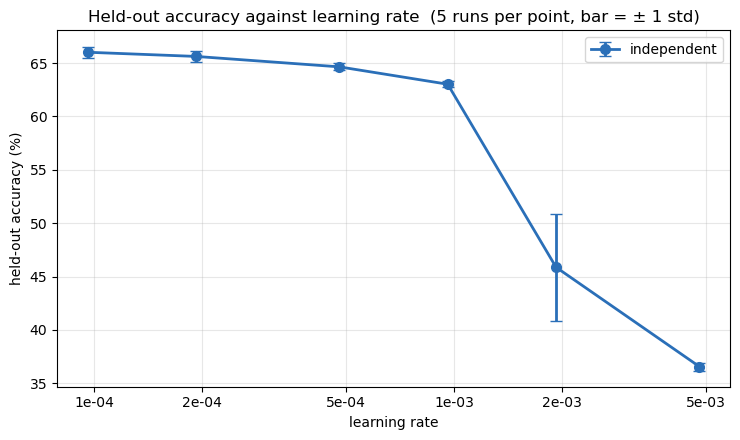

In [8]:
#N8: save the results (sweep and final runs), and plot the held-out accuracy against the learning rate
#    (when both notebooks are run in the same folder, the plot shows both networks)

np.savez('lr_sweep_early_stopping_independent.npz', lrs=np.array(LEARNING_RATES), best_lr=best_lr, patience=PATIENCE,
         accs=np.array([[r['ho_accs'] for r in results[lr]] for lr in LEARNING_RATES]),           # sweep, held-out: [lr, runs, 20]
         best_epoch=np.array([[r['best_epoch'] for r in results[lr]] for lr in LEARNING_RATES]),  # sweep: [lr, runs]
         stop_epoch=np.array([[r['stop_epoch'] for r in results[lr]] for lr in LEARNING_RATES]),
         tracc=np.array([[r['tr_acc'] for r in results[lr]] for lr in LEARNING_RATES]),
         final_test_accs=np.array([r['te_accs'] for r in final]),                                # final runs, test: [runs, 20]
         final_ho_accs=np.array([r['ho_accs'] for r in final]),
         final_test_loss=np.array([r['te_loss'] for r in final]),
         final_tracc=np.array([r['tr_acc'] for r in final]),
         final_best_epoch=np.array([r['best_epoch'] for r in final]),
         final_stop_epoch=np.array([r['stop_epoch'] for r in final]))
print("saved lr_sweep_early_stopping_independent.npz")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ticks = set()
for name, colour, shift in [('independent', '#2A6FB8', 0.96), ('compound', '#C8602C', 1.04)]:   # shift: a little sideways, so the bars do not hide each other
    if not os.path.exists(f'lr_sweep_early_stopping_{name}.npz'):
        continue
    r = np.load(f'lr_sweep_early_stopping_{name}.npz')
    per_run = r['accs'].mean(axis=2)                                   # [learning rates, runs]: mean over the 20 problems
    ax.errorbar(r['lrs'] * shift, per_run.mean(axis=1), yerr=per_run.std(axis=1), color=colour, lw=2,
                marker='o', ms=7, capsize=4, label=name)
    ticks.update(r['lrs'].tolist())
ax.set_xscale('log')
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(sorted(ticks))
ax.set_xticklabels([f'{lr:.0e}' for lr in sorted(ticks)])
ax.set_xlabel('learning rate')
ax.set_ylabel('held-out accuracy (%)')
ax.set_title(f'Held-out accuracy against learning rate  ({N_RUNS} runs per point, bar = ± 1 std)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()